# Week 14 · Phase-measuring deflectometry, step by step, on the SOLAR bench
**Deflectometry Learning Lab · ASU SOLAR** · Diego Bethancourth · Advisor: Dr. Xiangyu Guo

**Problem.** The bench hardware is not in the lab yet. Before it arrives, we want to know what the camera will see, how a mirror tilt becomes a number, and how small a tilt the bench can detect.

**Approach.** Build the bench in software with the Week 11 and Week 12 geometry, trace one light ray per camera pixel, generate the phase-shifted images the camera would record, then decode them with the same equations used on the real bench.

| Step | Name | Produces | Relation used |
|---|---|---|---|
| 1 | Bench geometry | Positions of camera, screen, 9 mirrors | Week 11 / Week 12 reports |
| 2 | Camera rays | One direction per pixel | Pinhole camera model |
| 3 | Ray hits a mirror | Point on the mirror | Ray–plane intersection |
| 4 | Reflection | Reflected direction | Law of reflection |
| 5 | Ray hits the screen | Screen pixel (u, v) seen by each camera pixel | Ray–plane intersection |
| 6 | Fringe images | The 4 phase-shifted camera frames | $I_k = A + B\cos(2\pi u/P + \delta_k)$ |
| 7 | Phase retrieval | Wrapped phase φ | 4-step formula (Week 1) |
| 8 | Unwrapping | Absolute screen coordinate | Three fringe periods |
| 9 | Slope | Surface normal and slope per pixel | Bisector of the two rays |
| 10 | Tip/tilt per mirror | One tilt value per segment | Digital aperture + mean |
| 11 | Experiments | Linearity, range limit, repeatability, sensitivity | Steps 1–10 repeated |

Run the cells in order (**Runtime → Run all** in Colab). Units: millimetres and radians; inches are given beside the inputs.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
TWO_PI = 2 * np.pi
rng = np.random.default_rng(14)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9})
MAROON, GOLD, GRAY = "#8C1D40", "#FFC627", "#747474"
def unit(v):
    # normalise vectors along the last axis
    return v / np.linalg.norm(v, axis=-1, keepdims=True)

## Step 1 · Bench geometry
Origin at the centre of the array, on the mirror face. **z** is the mirror normal (up), **x** is the line from the screen side to the camera side, **y** is along the long side of the screen.

| Symbol | Meaning | Value | Source |
|---|---|---|---|
| θ | Tilt of camera axis and screen normal from the mirror normal | 15° | WK12 step 1 |
| C | Lens front position (X, Y, Z) | (111.8, 0, 417.3) mm → 432 mm (17.0 in) from the centre | WK12 step 2 |
| S₀ | Screen centre | (−77.6, 0, 289.8) mm → 300 mm (11.8 in) | WK12 step 2 |
| f | Lens focal length | 25 mm | C23-2518-5M |
| p_c | Camera pixel | 3.45 µm, 2448 × 2048 px | acA2440-35um |
| p | Screen pixel pitch | 0.0896 mm, 3840 × 2160 px | WK11 (13 px → 1.165 mm) |
| a | Mirror side | 25.4 mm (1 in) | PFSQ10-03-G01 |
| g | Hole-grid spacing; the array is a 45° diamond | 25.4 mm → 35.9 mm diagonal pitch | WK12 CAD |
| A, B | Fringe bias and amplitude | 128, 100 grey levels | Lab convention |
| σ | Camera noise (assumption) | 2 grey levels | to be measured in E1 |

In [2]:
theta = np.deg2rad(15.0)
CAM   = np.array([111.8, 0.0, 417.3])   # lens front, mm
SCR_C = np.array([-77.6, 0.0, 289.8])   # screen centre, mm
f_mm, pix_cam = 25.0, 3.45e-3
NX_CAM, NY_CAM = 2448, 2048
p_scr = 0.0896
NU_SCR, NV_SCR = 3840, 2160
a_mir, g = 25.4, 25.4
A_lvl, B_lvl, refl, sigma_I = 128.0, 100.0, 0.90, 2.0

print("camera distance  =", round(np.linalg.norm(CAM), 1), "mm")
print("screen distance  =", round(np.linalg.norm(SCR_C), 1), "mm")
print("camera angle     =", round(np.degrees(np.arctan2(CAM[0], CAM[2])), 2), "deg")
print("screen angle     =", round(np.degrees(np.arctan2(-SCR_C[0], SCR_C[2])), 2), "deg")

# camera frame: optical axis zc points at the array centre, sensor long side along y
zc = unit(-CAM); yc = np.array([0.0, 1.0, 0.0]); xc = unit(np.cross(yc, zc))
# screen frame: normal ns points at the array centre; u along y (long side), v in the x-z plane
ns = unit(-SCR_C); eu = np.array([0.0, 1.0, 0.0]); ev = unit(np.cross(ns, eu))
SCR_O = SCR_C - (NU_SCR/2)*p_scr*eu - (NV_SCR/2)*p_scr*ev     # corner = screen pixel (0, 0)

# mirror centres: 3 x 3 grid rotated 45 degrees (diamond)
centres = np.array([[(i-j)*g, (i+j)*g, 0.0] for i in (-1, 0, 1) for j in (-1, 0, 1)])
names = [f"M{k}" for k in range(1, 10)]
for n_, c_ in zip(names, centres): print(n_, c_[:2])

camera distance  = 432.0 mm
screen distance  = 300.0 mm
camera angle     = 15.0 deg
screen angle     = 14.99 deg
M1 [  0.  -50.8]
M2 [-25.4 -25.4]
M3 [-50.8   0. ]
M4 [ 25.4 -25.4]
M5 [0. 0.]
M6 [-25.4  25.4]
M7 [50.8  0. ]
M8 [25.4 25.4]
M9 [ 0.  50.8]


**Check.** The camera and the screen sit at 15° on opposite sides of the mirror normal, so a flat mirror at the centre reflects the screen centre into the camera centre (law of reflection).

## Step 2 · Camera rays (pinhole model)
Each camera pixel (i, j) at sensor position (x_s, y_s) defines a ray from the lens through the point

$$\mathbf{d} = \frac{x_s\,\hat{\mathbf y}_c + y_s\,\hat{\mathbf x}_c + f\,\hat{\mathbf z}_c}{\lVert\cdot\rVert}$$

`binning = 2` uses every second pixel (1224 × 1024) so Colab runs in seconds. Use `binning = 1` for the full sensor.

In [3]:
def camera_rays(binning=2):
    nx, ny = NX_CAM // binning, NY_CAM // binning
    px = pix_cam * binning
    xs = (np.arange(nx) - nx/2 + 0.5) * px
    ys = (np.arange(ny) - ny/2 + 0.5) * px
    X, Y = np.meshgrid(xs, ys)
    return unit(Y[..., None]*xc + X[..., None]*yc + f_mm*zc)

rays = camera_rays(2)
print("rays:", rays.shape, " field of view =",
      round(2*np.degrees(np.arctan(NX_CAM*pix_cam/2/f_mm)), 1), "x",
      round(2*np.degrees(np.arctan(NY_CAM*pix_cam/2/f_mm)), 1), "deg")

rays: (1024, 1224, 3)  field of view = 19.2 x 16.1 deg


## Step 3 · Where each ray hits a mirror
Mirror s has centre **c**ₛ and unit normal **n**ₛ. A tilt is written as slopes (tₓ, t_y): $\mathbf n = (-\tan t_x, -\tan t_y, 1)/\lVert\cdot\rVert$.

The ray $\mathbf C + t\,\mathbf d$ meets the mirror plane at

$$t = \frac{(\mathbf c_s - \mathbf C)\cdot\mathbf n_s}{\mathbf d\cdot\mathbf n_s}$$

The hit counts only if the point lies inside the 25.4 mm square (rotated 45° like the array).

## Step 4 · Law of reflection
$$\mathbf r = \mathbf d - 2(\mathbf d\cdot\mathbf n)\,\mathbf n$$

A mirror tilt of α turns the reflected ray by **2α**: this doubling is why deflectometry is so sensitive.

## Step 5 · Where the reflected ray hits the screen
Same ray–plane intersection with the screen plane, then convert to screen pixels:
$u = (\mathbf Q - \mathbf S_0)\cdot\hat{\mathbf e}_u / p$, $v = (\mathbf Q - \mathbf S_0)\cdot\hat{\mathbf e}_v / p$.

In [4]:
def mirror_normal(tx, ty):
    return unit(np.array([-np.tan(tx), -np.tan(ty), 1.0]))

def trace(dirs, tilts):
    # returns: seg (mirror index, -1 = no mirror, -2 = mirror sees past the screen edge),
    #          hit (mirror index of any hit), M (point on mirror), S (screen u, v in px)
    H, W, _ = dirs.shape
    seg = -np.ones((H, W), int); hit = -np.ones((H, W), int)
    M = np.full((H, W, 3), np.nan); S = np.full((H, W, 2), np.nan)
    for s, c in enumerate(centres):
        n = mirror_normal(*tilts[s])
        t = ((c - CAM) @ n) / (dirs @ n)                    # Step 3
        P = CAM + t[..., None]*dirs
        e1 = np.array([1, 1, 0.0])/np.sqrt(2); e1 = unit(e1 - (e1 @ n)*n); e2 = np.cross(n, e1)
        inside = (np.abs((P-c) @ e1) <= a_mir/2) & (np.abs((P-c) @ e2) <= a_mir/2)
        r = dirs - 2*(dirs @ n)[..., None]*n                 # Step 4
        ts = ((SCR_O - P) @ ns) / (r @ ns)                   # Step 5
        Q = P + ts[..., None]*r
        u = ((Q - SCR_O) @ eu)/p_scr; v = ((Q - SCR_O) @ ev)/p_scr
        on = (u >= 0) & (u < NU_SCR) & (v >= 0) & (v < NV_SCR)
        seg[inside] = np.where(on[inside], s, -2); hit[inside] = s
        M[inside] = P[inside]; S[inside] = np.stack([u, v], -1)[inside]
    return seg, hit, M, S

flat = np.zeros((9, 2))
seg, hit, M, S = trace(rays, flat)
print("Fringe coverage of each mirror (share of its image that sees the screen):")
for s in range(9):
    print(f"  {names[s]}: {100*(seg==s).sum()/max((hit==s).sum(),1):5.1f} %")
du = np.nanmedian(np.abs(np.diff(S[..., 0], axis=1))[seg[:, 1:] == 4])
print("camera pixels per 13-px fringe (full sensor):", round(13/du*2, 2))

Fringe coverage of each mirror (share of its image that sees the screen):
  M1: 100.0 %
  M2: 100.0 %
  M3:  92.9 %
  M4: 100.0 %
  M5: 100.0 %
  M6: 100.0 %
  M7:  87.1 %
  M8: 100.0 %
  M9: 100.0 %
camera pixels per 13-px fringe (full sensor): 11.53


**Result.** Seven mirrors see the screen over their whole face; the two corner mirrors on the camera–screen line see it over 93 % and 87 %. Week 12 found 93 % and 77 % in CAD (open item: check the screen active area used in each). One 13-pixel fringe spans about 11.5 camera pixels, which matches the Week 11 estimate of about 12.

## Step 6 · The fringe images the camera records
The screen shows $I_k(u) = A + B\cos(2\pi u/P + \delta_k)$ with $\delta_k = 2\pi k/4$, k = 0…3 (lab convention). Each camera pixel records the screen pixel (u, v) found in Step 5, times the mirror reflectance (0.90), plus noise, rounded to 8 bits.

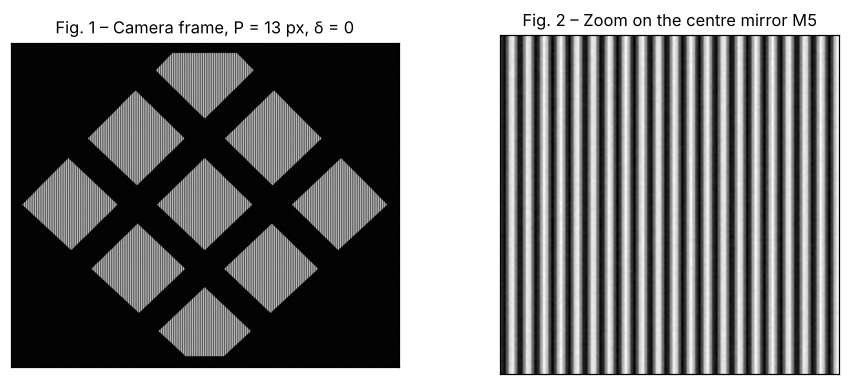

In [5]:
def render(seg, coord, P, delta, noise=True):
    I = np.where(seg >= 0, refl*(A_lvl + B_lvl*np.cos(TWO_PI*coord/P + delta)), 3.0)
    if noise: I = I + rng.normal(0, sigma_I, I.shape)
    return np.clip(np.round(I), 0, 255)

frames = [render(seg, S[..., 0], 13.0, TWO_PI*k/4) for k in range(4)]
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].imshow(frames[0], cmap="gray"); ax[0].set_title("Fig. 1 – Camera frame, P = 13 px, δ = 0")
h, w = frames[0].shape
ax[1].imshow(frames[0][h//2-60:h//2+60, w//2-60:w//2+60], cmap="gray"); ax[1].set_title("Fig. 2 – Zoom on the centre mirror M5")
for x in ax: x.set_xticks([]); x.set_yticks([])
plt.show()

## Step 7 · Phase retrieval (the Week 1 formula)
With N = 4 steps:

$$\varphi = \operatorname{atan2}\!\Big(-\sum_k I_k\sin\delta_k,\ \sum_k I_k\cos\delta_k\Big) = \operatorname{atan2}(I_4 - I_2,\ I_1 - I_3)$$

The modulation $B' = \tfrac{2}{N}\sqrt{(\sum I_k\sin\delta_k)^2 + (\sum I_k\cos\delta_k)^2}$ tells which pixels hold a fringe (mask).

φ is known only between −π and π: it repeats every fringe. That is the **wrapping** problem.

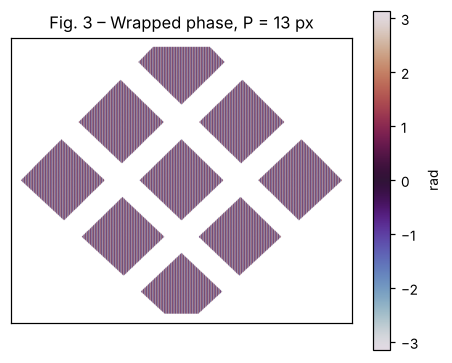

mean modulation on the mirrors: 90.0 grey levels (expected 0.9 x 100 = 90)


In [6]:
def phase(frames, N=4):
    d = TWO_PI*np.arange(N)/N
    Ss = sum(I*np.sin(dk) for I, dk in zip(frames, d)); Cs = sum(I*np.cos(dk) for I, dk in zip(frames, d))
    return np.arctan2(-Ss, Cs), 2/N*np.hypot(Ss, Cs)

phi13, mod = phase(frames)
plt.figure(figsize=(5, 4)); plt.imshow(np.where(seg >= 0, phi13, np.nan), cmap="twilight")
plt.colorbar(label="rad"); plt.title("Fig. 3 – Wrapped phase, P = 13 px"); plt.xticks([]); plt.yticks([]); plt.show()
print("mean modulation on the mirrors:", round(float(mod[seg >= 0].mean()), 1), "grey levels (expected 0.9 x 100 = 90)")

## Step 8 · Unwrapping with three periods
Show three fringe sets per axis: one period slightly longer than the screen (4224 px), then 104 px, then 13 px. The coarse phase gives an approximate position; each finer set adds precision. At each level

$$k = \operatorname{round}\!\Big(\frac{u_{\text{prev}}\,2\pi/P - \varphi}{2\pi}\Big),\qquad u = \frac{(\varphi + 2\pi k)\,P}{2\pi}$$

This works while the error of the previous level stays below half of the next period.

In [7]:
def absolute_coord(seg, coord, periods, n_panel, noise=True):
    est = None
    for P in periods:
        fr = [render(seg, coord, P, TWO_PI*k/4, noise) for k in range(4)]
        phi, mod = phase(fr)
        if est is None:
            est = np.mod(phi, TWO_PI)*P/TWO_PI
            est = np.where(est > n_panel + (P - n_panel)/2, est - P, est)   # noise near pixel 0
        else:
            k = np.round((est*TWO_PI/P - phi)/TWO_PI)
            est = (phi + TWO_PI*k)*P/TWO_PI
    return est, mod, phi

PU, PV = [4224.0, 104.0, 13.0], [2376.0, 104.0, 13.0]
u_abs, mod_u, phi_u = absolute_coord(seg, S[..., 0], PU, NU_SCR)
v_abs, mod_v, phi_v = absolute_coord(seg, S[..., 1], PV, NV_SCR)
err = (u_abs - S[..., 0])[seg >= 0]
print("error of the decoded u: RMS =", round(float(np.sqrt(np.mean(err**2))), 3), "screen px =",
      round(float(np.sqrt(np.mean(err**2)))*p_scr*1000, 2), "um on the screen")

error of the decoded u: RMS = 0.033 screen px = 2.94 um on the screen


## Step 9 · Slope from the two rays
For each camera pixel we now know three points: the camera **C**, the mirror point **M**, and the screen point **Q** it sees. The surface normal bisects the incoming and outgoing rays:

$$\mathbf n = \frac{\hat{\mathbf r}_{out} - \hat{\mathbf r}_{in}}{\lVert\cdot\rVert},\quad \hat{\mathbf r}_{in} = \frac{\mathbf M - \mathbf C}{\lVert\cdot\rVert},\ \hat{\mathbf r}_{out} = \frac{\mathbf Q - \mathbf M}{\lVert\cdot\rVert},\qquad \text{slope}_x = -\frac{n_x}{n_z},\ \text{slope}_y = -\frac{n_y}{n_z}$$

**M** is taken on the nominal plane z = 0. Deflectometry cannot tell height and slope apart from one view (height ambiguity); for a 1 mrad tilt about the segment centre the edge moves 13 µm, which is negligible here.

## Step 10 · Digital aperture and tip/tilt per segment
Keep the pixels of one mirror, erode its edge by 1 mm (Week 11 defocus blur), drop pixels with weak modulation, then average the slopes.

recovered tip/tilt (urad):
  M1: x    -0.04   y    -0.02
  M2: x    -0.06   y    -0.00
  M3: x     0.02   y    -0.02
  M4: x     0.05   y     0.03
  M5: x   500.00   y     0.47
  M6: x     0.03   y     0.01
  M7: x    -0.03   y    -0.00
  M8: x    -0.00   y     0.03
  M9: x    -0.01   y    -0.02


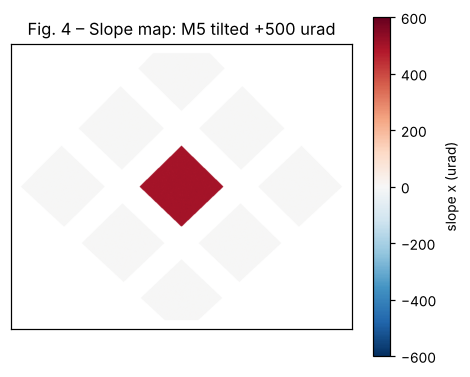

In [8]:
def slopes(M, u, v):
    Q = SCR_O + u[..., None]*p_scr*eu + v[..., None]*p_scr*ev
    Mz = M.copy(); Mz[..., 2] = 0.0
    rin = unit(Mz - CAM); rout = unit(Q - Mz); n = unit(rout - rin)
    return -n[..., 0]/n[..., 2], -n[..., 1]/n[..., 2]

def aperture(seg, s, M, erode=1.0):
    r = M[..., :2] - centres[s][:2]
    a1 = np.abs(r @ (np.array([1, 1])/np.sqrt(2))); a2 = np.abs(r @ (np.array([-1, 1])/np.sqrt(2)))
    lim = a_mir/2 - erode
    return (seg == s) & (a1 <= lim) & (a2 <= lim)

def measure(tilts, rays, noise=True):
    seg, hit, M, S = trace(rays, tilts)
    u, mu, phu = absolute_coord(seg, S[..., 0], PU, NU_SCR, noise)
    v, mv, phv = absolute_coord(seg, S[..., 1], PV, NV_SCR, noise)
    sx, sy = slopes(M, u, v)
    ok = (mu > 0.5*refl*B_lvl) & (mv > 0.5*refl*B_lvl)
    tt = np.array([[np.nanmean(sx[aperture(seg, s, M) & ok]), np.nanmean(sy[aperture(seg, s, M) & ok])] for s in range(9)])
    return tt, dict(seg=seg, M=M, S=S, sx=sx, sy=sy, phu=phu, phv=phv)

T = flat.copy(); T[4] = [500e-6, 0.0]          # tilt M5 by +500 urad (slope in x)
tt, out = measure(T, rays)
print("recovered tip/tilt (urad):")
for s in range(9): print(f"  {names[s]}: x {tt[s,0]*1e6:8.2f}   y {tt[s,1]*1e6:8.2f}")
plt.figure(figsize=(5, 4)); plt.imshow(np.where(out["seg"] >= 0, out["sx"]*1e6, np.nan), cmap="RdBu_r", vmin=-600, vmax=600)
plt.colorbar(label="slope x (urad)"); plt.title("Fig. 4 – Slope map: M5 tilted +500 urad"); plt.xticks([]); plt.yticks([]); plt.show()

## Step 11 · Experiments in simulation
### 11a · Linearity (E2) and the half-fringe limit
Command a tilt α on M5 and compare the recovered value with two decoders:
- **single period** (P = 13 px only, phase difference against the flat reference, no unwrapping);
- **three periods** (Step 8).

A tilt α moves the reflected ray by 2α, so the spot on the screen moves about $2\alpha z_d$. The single-period decoder fails once that shift passes half a fringe:

$$\alpha_{max} = \frac{P_f/2}{2 z_d} = \frac{1.165/2}{2 \times 300} \approx 0.97\ \text{mrad} = 971\ \mu\text{rad}$$

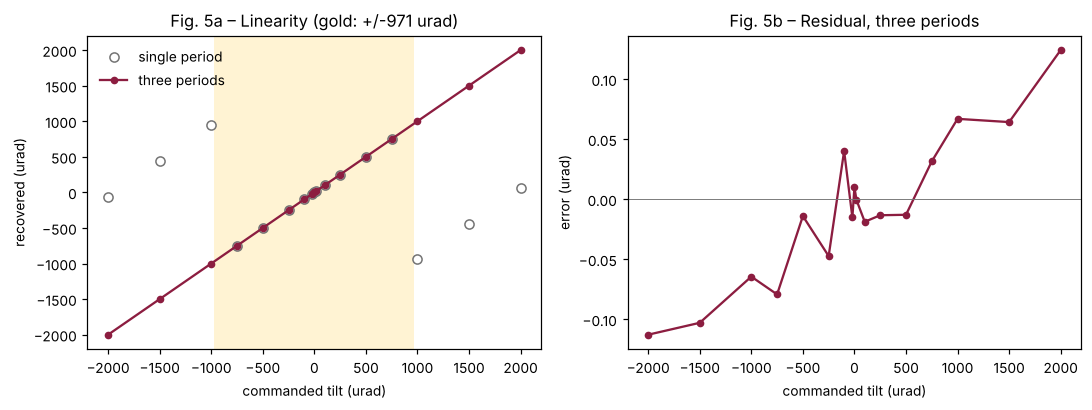

In [9]:
ref_tt, ref = measure(flat, rays)
cmds = np.array([-2000, -1500, -1000, -750, -500, -250, -100, -20, 0, 20, 100, 250, 500, 750, 1000, 1500, 2000])*1e-6
full, single = [], []
for c in cmds:
    T = flat.copy(); T[4] = [c, 0.0]
    tt, o = measure(T, rays)
    full.append((tt[4, 0] - ref_tt[4, 0])*1e6)
    ap = aperture(o["seg"], 4, o["M"]) & aperture(ref["seg"], 4, ref["M"])
    dphu = np.angle(np.exp(1j*(o["phu"] - ref["phu"]))); dphv = np.angle(np.exp(1j*(o["phv"] - ref["phv"])))
    sx1, _ = slopes(ref["M"], ref["S"][..., 0] + dphu*13/TWO_PI, ref["S"][..., 1] + dphv*13/TWO_PI)
    sx0, _ = slopes(ref["M"], ref["S"][..., 0], ref["S"][..., 1])
    single.append(np.nanmean(sx1[ap] - sx0[ap])*1e6)
full, single = np.array(full), np.array(single)
lim = 1.165/2/(2*300)*1e6
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].axvspan(-lim, lim, color=GOLD, alpha=.2, lw=0)
ax[0].plot(cmds*1e6, single, "o", mfc="white", mec=GRAY, label="single period")
ax[0].plot(cmds*1e6, full, "o-", color=MAROON, ms=4, label="three periods")
ax[0].set_xlabel("commanded tilt (urad)"); ax[0].set_ylabel("recovered (urad)"); ax[0].legend(frameon=False)
ax[0].set_title(f"Fig. 5a – Linearity (gold: +/-{lim:.0f} urad)")
ax[1].plot(cmds*1e6, full - cmds*1e6, "o-", color=MAROON, ms=4); ax[1].axhline(0, color=GRAY, lw=.6)
ax[1].set_xlabel("commanded tilt (urad)"); ax[1].set_ylabel("error (urad)"); ax[1].set_title("Fig. 5b – Residual, three periods")
plt.tight_layout(); plt.show()

### 11b · Repeatability (E1), camera noise only
Repeat the flat measurement several times with fresh noise. The spread is the floor set by camera noise alone. On the real bench, vibration, air currents and warm-up add to it, so E1 measures the real value. Raise `n_rep` to 30 to match E1 (about 1 minute per capture at `binning = 1`).

In [10]:
n_rep = 5
rep = np.array([measure(flat, rays)[0]*1e6 for _ in range(n_rep)])
print("standard deviation over", n_rep, "captures (urad):")
for s in range(9): print(f"  {names[s]}: x {rep[:, s, 0].std(ddof=1):.3f}   y {rep[:, s, 1].std(ddof=1):.3f}")

standard deviation over 5 captures (urad):
  M1: x 0.031   y 0.007
  M2: x 0.031   y 0.046
  M3: x 0.016   y 0.032
  M4: x 0.035   y 0.033
  M5: x 0.031   y 0.015
  M6: x 0.014   y 0.211
  M7: x 0.016   y 0.020
  M8: x 0.018   y 0.030
  M9: x 0.023   y 0.052


### 11c · Which bench measurements matter
Decode a 1000 µrad tilt with a slightly wrong geometry and see what changes. A reference capture of the flat array is subtracted, as SMOTS does.

In [11]:
T1 = flat.copy(); T1[4] = [1000e-6, 0.0]
tt1, o1 = measure(T1, rays, noise=False); tt0, o0 = measure(flat, rays, noise=False)
def decode_with(scr_shift=0.0, cam_shift=0.0, pitch_scale=1.0):
    global SCR_O, CAM, p_scr
    saved = SCR_O.copy(), CAM.copy(), p_scr
    SCR_O = SCR_O - scr_shift*ns; CAM = CAM + cam_shift*unit(CAM); p_scr = p_scr*pitch_scale
    # the decoded screen pixels are the same; only the geometry used to turn them into rays is wrong
    u1, v1 = o1["S"][..., 0], o1["S"][..., 1]
    u0, v0 = o0["S"][..., 0], o0["S"][..., 1]
    s1, _ = slopes(o1["M"], u1, v1); s0, _ = slopes(o0["M"], u0, v0)
    ap1 = aperture(o1["seg"], 4, o1["M"]); ap0 = aperture(o0["seg"], 4, o0["M"])
    out = (np.nanmean(s1[ap1]) - np.nanmean(s0[ap0]))*1e6, np.nanmean(s0[ap0])*1e6
    SCR_O, CAM, p_scr = saved
    return out
for lab, kw in [("nominal", {}), ("screen 1 mm farther", dict(scr_shift=1.0)),
                ("camera 2 mm farther", dict(cam_shift=2.0)), ("pixel pitch +0.5 %", dict(pitch_scale=1.005))]:
    d, a = decode_with(**kw)
    print(f"{lab:22s} tilt with reference subtracted = {d:8.2f} urad   absolute slope of the flat = {a:8.2f} urad")

nominal                tilt with reference subtracted =  1000.06 urad   absolute slope of the flat =     0.00 urad


screen 1 mm farther    tilt with reference subtracted =   996.75 urad   absolute slope of the flat =     0.14 urad


camera 2 mm farther    tilt with reference subtracted =  1000.06 urad   absolute slope of the flat =    -0.85 urad


pixel pitch +0.5 %     tilt with reference subtracted =  1005.04 urad   absolute slope of the flat =  -807.71 urad


**Reading.** With the reference subtracted, a 1 mm error in the screen distance changes the result by about 0.3 % (it scales as 1/z_d), and a 0.5 % pixel-pitch error by 0.5 %. Without the reference, the same pitch error shifts the absolute slope by hundreds of µrad. This is why the experiments compare each capture with a flat reference.

## Summary
| Quantity | Simulated value |
|---|---|
| Camera px per fringe (P = 13 px) | 11.5 |
| Mirrors fully covered by fringes | 7 of 9 (corners 93 % and 87 %) |
| Range with one period | ±971 µrad |
| Range with three periods | linear to ±2000 µrad, error < 0.2 µrad |
| Repeatability, camera noise only | below 0.1 µrad (floor, not the bench value) |
| Gain error per mm of screen distance | ≈ 0.3 % |

**Limits of this model.** Pinhole camera (no defocus blur), perfect flat mirrors, no screen gamma, no vibration or air turbulence, mirror heights all at z = 0. Each of these can be added one at a time in later weeks.